# Task 2 — Notebook 2: Proposed Model (Graph Neural Network)
**Project:** Motor-Imagery EEG Classification Using Graph Neural Networks with Functional Channel Connectivity
**Dataset:** BCI Competition IV — dataset 2a

This notebook reads its result files from `Task2_Results` to build the comparison.

| Step | Section |
|---|---|
| 1. EEG channels become graph nodes | 4, 6 |
| 2. Connectivity between channels becomes graph edges | 5, 6 |
| 3. Graph data prepared for the GNN | 7 |
| 4. GNN built and trained | 8, 9 |
| 5. Accuracy, precision, recall, F1, confusion matrix, ROC, PR | 10 |
| First results against the baselines, graph ablation, leave-one-subject-out | 11–13 |

Preprocessing, the subject split and the 11 per-channel features are identical to Notebook 1, so any difference in score comes from the model, not from the data.

## 1. Setup


In [1]:
!pip -q install torch_geometric

In [2]:
import os, json, time, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    confusion_matrix, roc_curve, auc, roc_auc_score,
    precision_recall_curve, average_precision_score, f1_score, recall_score,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED)

In [3]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", DEVICE)

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

PyTorch 2.14.1+cu130 | device: cuda


In [4]:
from google.colab import drive
drive.mount("/content/drive")

# Same folder as Task 1
DATA_DIR = "/content/drive/MyDrive/475_mini_proj"

Mounted at /content/drive


In [33]:
PROCESSED_DIR = os.path.join(DATA_DIR, "Processed_Data")   # written by Task 1
RESULTS_DIR   = os.path.join(DATA_DIR, "Task2_Results")    # written by Task 2
FIG_DIR       = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def finish(fig, fname):
    """Save a figure to Drive and show it."""
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, fname), dpi=150, bbox_inches="tight")
    plt.show()

In [6]:
METRIC_COLS = ["Accuracy", "Balanced acc", "Precision (macro)", "Recall (macro)", "F1 (macro)",
               "Precision (weighted)", "Recall (weighted)", "F1 (weighted)", "ROC-AUC (macro OvR)", "PR-AUC (macro OvR)"]

def compute_metrics(y_true, proba):
    y_pred = proba.argmax(1)
    Yb = label_binarize(y_true, classes=np.arange(N_CLASSES))
    pm, rm, fm, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, y_pred), "Balanced acc": balanced_accuracy_score(y_true, y_pred),
        "Precision (macro)": pm, "Recall (macro)": rm, "F1 (macro)": fm,
        "Precision (weighted)": pw, "Recall (weighted)": rw, "F1 (weighted)": fw,
        "ROC-AUC (macro OvR)": roc_auc_score(Yb, proba, average="macro"),
        "PR-AUC (macro OvR)": average_precision_score(Yb, proba, average="macro"),
    }

def per_class_table(y_true, proba):
    y_pred = proba.argmax(1)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(N_CLASSES), zero_division=0)
    Yb = label_binarize(y_true, classes=np.arange(N_CLASSES))
    rows = [{"class": CLASS_NAMES[c], "precision": p[c], "recall": r[c], "f1-score": f[c],
             "ROC-AUC": roc_auc_score(Yb[:, c], proba[:, c]), "support": int(s[c])} for c in range(N_CLASSES)]
    for avg in ["macro", "weighted"]:
        pa, ra, fa, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        rows.append({"class": f"{avg} avg", "precision": pa, "recall": ra, "f1-score": fa,
                     "ROC-AUC": roc_auc_score(Yb, proba, average=avg), "support": int(s.sum())})
    return pd.DataFrame(rows).set_index("class")

def plot_confusion(ax, y_true, y_pred, title, ylabel=True):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=8); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("Predicted class"); ax.set_title(title, fontsize=10)
    if ylabel:
        ax.set_ylabel("True class")
    else:
        ax.set_yticklabels([])
    return im

def read_confusion(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES)).astype(float)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    rec = np.diag(cmn); off = cmn.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"Reading ({name}): best-recognised class = {CLASS_NAMES[rec.argmax()]} (recall {rec.max():.2f}); "
          f"weakest = {CLASS_NAMES[rec.argmin()]} (recall {rec.min():.2f}); "
          f"most common mistake = true '{CLASS_NAMES[i]}' predicted as '{CLASS_NAMES[j]}' ({off[i, j]:.0%} of those trials).")

def plot_ovr_curves(y_true, proba, model_name, fname):
    """One-vs-rest ROC and precision-recall curves for one model."""
    Yb = label_binarize(y_true, classes=np.arange(N_CLASSES))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    aucs, aps = [], []
    for c, cname in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(Yb[:, c], proba[:, c]); aucs.append(auc(fpr, tpr))
        axes[0].plot(fpr, tpr, lw=2, label=f"{cname} (AUC = {aucs[-1]:.2f})")
        pr, rc, _ = precision_recall_curve(Yb[:, c], proba[:, c]); aps.append(average_precision_score(Yb[:, c], proba[:, c]))
        axes[1].plot(rc, pr, lw=2, label=f"{cname} (AP = {aps[-1]:.2f})")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.50)")
    axes[0].set(title=f"{model_name}: one-vs-rest ROC curves (test subjects)", xlabel="False positive rate", ylabel="True positive rate")
    prev = Yb.mean()
    axes[1].axhline(prev, color="k", ls="--", lw=1, label=f"Chance (AP = {prev:.2f})")
    axes[1].set(title=f"{model_name}: one-vs-rest precision-recall curves (test subjects)", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
    axes[0].legend(loc="lower right"); axes[1].legend(loc="upper right")
    finish(fig, fname)
    print(f"Reading ({model_name}): every curve above the dashed line means the model ranks that class better than chance. "
          f"Easiest class to separate = {CLASS_NAMES[int(np.argmax(aucs))]} (AUC {max(aucs):.2f}, AP {aps[int(np.argmax(aucs))]:.2f}); "
          f"hardest = {CLASS_NAMES[int(np.argmin(aucs))]} (AUC {min(aucs):.2f}, AP {aps[int(np.argmin(aucs))]:.2f}). "
          f"Macro AUC = {np.mean(aucs):.3f}; chance is 0.50 for AUC and {prev:.2f} for AP.")

## 2. Load the Task 1 data and preprocess (same as Notebook 1)
Drop the 3 EOG channels, band-pass 4–40 Hz per trial, keep 0.5–4.0 s after the cue, encode the labels.

In [7]:
CLASS_CODES = {"Left hand": 769, "Right hand": 770, "Both feet": 771, "Tongue": 772}

def load_from_gdf(data_dir):
    """Fallback: rebuild the Task 1 epochs straight from the A0xT.gdf files."""
    import re, subprocess, sys
    try:
        import mne
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mne"], check=True)
        import mne
    paths = sorted(
        os.path.join(r, f) for r, _, fs in os.walk(data_dir) for f in fs
        if re.search(r"^A\d{2}T\.gdf$", f, re.I)
    )
    assert paths, "No A0xT.gdf files found under DATA_DIR."
    Xs, ys, subs, chs, sf = [], [], [], None, None
    for p in paths:
        raw = mne.io.read_raw_gdf(p, preload=True, verbose="ERROR")
        events, ann = mne.events_from_annotations(raw, verbose="ERROR")
        c2e = {int(d): e for d, e in ann.items() if str(d).isdigit()}
        ev_id = {lab: c2e[c] for lab, c in CLASS_CODES.items()}
        ep = mne.Epochs(raw, events, event_id=ev_id, tmin=0.0, tmax=3.996, baseline=None,
                        preload=True, verbose="ERROR")
        inv = {v: k for k, v in ev_id.items()}
        Xs.append(ep.get_data(units="uV").astype(np.float32))
        ys.append(np.array([inv[c] for c in ep.events[:, 2]]))
        subs.append(np.array([os.path.basename(p)[:3]] * len(ep)))
        chs, sf = ep.ch_names, ep.info["sfreq"]
        print(os.path.basename(p), Xs[-1].shape)
    return np.concatenate(Xs), np.concatenate(ys), np.concatenate(subs), list(chs), float(sf)

npz_path = os.path.join(PROCESSED_DIR, "eeg_epochs.npz")
if os.path.exists(npz_path):
    d = np.load(npz_path)
    X_raw, y_names = d["X"], d["y"].astype(str)
    subjects = pd.read_csv(os.path.join(PROCESSED_DIR, "eeg_metadata.csv"))["subject"].astype(str).values
    cfg = json.load(open(os.path.join(PROCESSED_DIR, "eeg_config.json")))
    channel_names, sfreq = cfg["channel_names"], float(cfg["sampling_frequency"])
    print("Loaded the Task 1 export from", PROCESSED_DIR)
else:
    print("Task 1 export not found -> re-reading the GDF files (takes a few minutes).")
    X_raw, y_names, subjects, channel_names, sfreq = load_from_gdf(DATA_DIR)

assert len(X_raw) == len(y_names) == len(subjects)
print("Epochs:", X_raw.shape, "| sampling rate:", sfreq, "Hz | subjects:", sorted(set(subjects)))

Loaded the Task 1 export from /content/drive/MyDrive/475_mini_proj/Processed_Data
Epochs: (2592, 25, 1000) | sampling rate: 250.0 Hz | subjects: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']


In [8]:
# --- 1. keep the 22 EEG channels, drop the 3 EOG channels -------------------
STD_22 = ["Fz", "FC3", "FC1", "FCz", "FC2", "FC4", "C5", "C3", "C1", "Cz", "C2", "C4", "C6",
          "CP3", "CP1", "CPz", "CP2", "CP4", "P1", "Pz", "P2", "POz"]   # official 2a montage order
eeg_idx = [i for i, ch in enumerate(channel_names) if "EOG" not in ch.upper()]
assert len(eeg_idx) == 22, f"Expected 22 EEG channels, found {len(eeg_idx)}"
ch_names = STD_22
N_CH = 22

# --- 2. data-quality check (Task 1 found no NaN/Inf; we re-check) -----------
n_bad = int((~np.isfinite(X_raw)).sum())
print("Non-finite samples:", n_bad)
if n_bad:
    X_raw = np.nan_to_num(X_raw, nan=0.0, posinf=0.0, neginf=0.0)

# --- 3. band-pass 4-40 Hz, one trial at a time, then keep 0.5-4.0 s after the cue
def bandpass(X, lo, hi, fs, order=4):
    sos = butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return sosfiltfilt(sos, X, axis=-1).astype(np.float32)

T0, T1 = int(0.5 * sfreq), int(4.0 * sfreq)
Xf = bandpass(X_raw[:, eeg_idx, :], 4.0, 40.0, sfreq)[:, :, T0:T1]
del X_raw

# --- 4. label encoding (fixed order so both notebooks agree) ----------------
CLASS_NAMES = ["Left hand", "Right hand", "Both feet", "Tongue"]
N_CLASSES = len(CLASS_NAMES)
y = np.array([CLASS_NAMES.index(c) for c in y_names])

print("Clean epochs:", Xf.shape, "(trials, channels, samples)")
print("Label encoding:", dict(enumerate(CLASS_NAMES)))

Non-finite samples: 0
Clean epochs: (2592, 22, 875) (trials, channels, samples)
Label encoding: {0: 'Left hand', 1: 'Right hand', 2: 'Both feet', 3: 'Tongue'}


## 3. Subject-independent split — done **before** any graph is built
Train A01–A06, validation A07, test A08–A09. The graph in section 6 is computed from the training subjects only. Building it from all nine subjects and splitting afterwards would let the test subjects shape the connections the model learns on.

In [9]:
TRAIN_SUBJECTS = ["A01", "A02", "A03", "A04", "A05", "A06"]
VAL_SUBJECTS   = ["A07"]
TEST_SUBJECTS  = ["A08", "A09"]

assert not (set(TRAIN_SUBJECTS) & set(VAL_SUBJECTS)) and not (set(TRAIN_SUBJECTS) & set(TEST_SUBJECTS)) \
       and not (set(VAL_SUBJECTS) & set(TEST_SUBJECTS)), "A subject appears in more than one split!"

tr_idx = np.where(np.isin(subjects, TRAIN_SUBJECTS))[0]
va_idx = np.where(np.isin(subjects, VAL_SUBJECTS))[0]
te_idx = np.where(np.isin(subjects, TEST_SUBJECTS))[0]
y_train, y_val, y_test = y[tr_idx], y[va_idx], y[te_idx]

split_table = pd.DataFrame([
    {"split": name, "subjects": ", ".join(s), "trials": len(i),
     **{CLASS_NAMES[c]: int((y[i] == c).sum()) for c in range(N_CLASSES)}}
    for name, s, i in [("train", TRAIN_SUBJECTS, tr_idx), ("validation", VAL_SUBJECTS, va_idx), ("test", TEST_SUBJECTS, te_idx)]
])
display(split_table)
imb = split_table[CLASS_NAMES].max(axis=1) / split_table[CLASS_NAMES].min(axis=1)
print(f"Reading: no subject is shared between splits. Largest class / smallest class ratio per split = "
      f"{imb.round(2).tolist()} -> {'balanced, no resampling needed' if imb.max() < 1.5 else 'IMBALANCED: rely on macro-F1 and per-class recall'}.")

,split,subjects,trials,Left hand,Right hand,Both feet,Tongue
0,train,"A01, A02, A03, A04, A05, A06",1728,432,432,432,432
1,validation,A07,288,72,72,72,72
2,test,"A08, A09",576,144,144,144,144


Reading: no subject is shared between splits. Largest class / smallest class ratio per split = [1.0, 1.0, 1.0] -> balanced, no resampling needed.


## 4. Node features
Each of the 22 electrodes gets the same 11 numbers used in Notebook 1 (log-variance, relative and log band power in theta / mu-alpha / beta / gamma, Hjorth mobility and complexity). They are computed from one trial at a time. They are standardised later with the mean and standard deviation of the **training subjects** only.

In [10]:
BANDS = {"theta": (4, 8), "mu_alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}   # same bands as Task 1
_trapz = getattr(np, "trapezoid", None) or np.trapz

def channel_features(X, fs):
    """Per-trial, per-channel features. X: (trials, channels, samples) -> (trials, channels, 11)."""
    eps = 1e-12
    freqs, psd = welch(X, fs=fs, nperseg=256, axis=-1)
    full = (freqs >= 4) & (freqs <= 40)
    total = _trapz(psd[..., full], freqs[full], axis=-1) + eps
    feats, names = [np.log(X.var(axis=-1) + eps)], ["logvar"]
    for b, (lo, hi) in BANDS.items():
        m = (freqs >= lo) & (freqs < hi)
        bp = _trapz(psd[..., m], freqs[m], axis=-1) + eps
        feats += [bp / total, np.log(bp)]
        names += [f"{b}_relpower", f"{b}_logpower"]
    d1 = np.diff(X, axis=-1); d2 = np.diff(d1, axis=-1)
    v0, v1, v2 = X.var(-1) + eps, d1.var(-1) + eps, d2.var(-1) + eps
    mob = np.sqrt(v1 / v0)
    feats += [mob, np.sqrt(v2 / v1) / mob]
    names += ["hjorth_mobility", "hjorth_complexity"]
    return np.stack(feats, axis=-1).astype(np.float32), names

node_feats, FEAT_NAMES = channel_features(Xf, sfreq)          # (trials, 22, 11)
N_FEAT = len(FEAT_NAMES)
print("Per-channel feature tensor:", node_feats.shape)
print("Features per channel:", FEAT_NAMES)

Per-channel feature tensor: (2592, 22, 11)
Features per channel: ['logvar', 'theta_relpower', 'theta_logpower', 'mu_alpha_relpower', 'mu_alpha_logpower', 'beta_relpower', 'beta_logpower', 'gamma_relpower', 'gamma_logpower', 'hjorth_mobility', 'hjorth_complexity']


## 5. Functional connectivity between channels
For every trial: band-pass to 8–30 Hz (the mu and beta rhythms that motor imagery modulates), then the absolute Pearson correlation between every pair of channels. This gives one 22 × 22 matrix per trial. A high value means the two electrodes rise and fall together during that trial.

Each matrix uses only its own trial, so this step is safe before or after the split. What must respect the split is the *averaging* in the next section.

In [11]:
X_mb = bandpass(Xf, 8.0, 30.0, sfreq)
Z = X_mb - X_mb.mean(axis=-1, keepdims=True)
Z /= (Z.std(axis=-1, keepdims=True) + 1e-8)
CONN = np.abs(np.matmul(Z, Z.transpose(0, 2, 1)) / Z.shape[-1]).astype(np.float32)   # (trials, 22, 22)
del X_mb, Z
print("Per-trial connectivity:", CONN.shape, "| value range:", float(CONN.min().round(3)), "to", float(CONN.max().round(3)))

Per-trial connectivity: (2592, 22, 22) | value range: 0.0 to 1.0


## 6. (A) Graph construction

| Element | Choice | Why it fits |
|---|---|---|
| **Graph** | one graph per trial; the label of the graph is the imagined movement | the task is to classify a trial, so it is graph classification |
| **Nodes** | the 22 EEG electrodes | each electrode measures one patch of cortex; hand, foot and tongue imagery change activity at different patches |
| **Node features** | 11 spectral / statistical values per electrode (section 4) | band power over the motor cortex is the known signature of motor imagery (Task 1, EDA E–G) |
| **Edges** | each electrode is linked to the 6 electrodes it correlates with most strongly; links are made symmetric | motor imagery is produced by regions working together, and Task 1 showed neighbouring channels carry strongly related signals (63 pairs with r ≥ 0.90) |
| **Edge weights** | the mean absolute 8–30 Hz correlation of the pair | stronger functional coupling → that neighbour counts more when messages are averaged |
| **Leakage rule** | the mean connectivity is taken over **training-subject trials only**; the same graph is then applied to validation and test trials | the test subjects have no influence on which electrodes are connected |

The edge structure is therefore shared by all trials (a "group" functional graph), and the node features change from trial to trial. Section 12 tests two alternatives: a different graph for every trial, and no edges at all.

In [12]:
K_NEIGHBORS = 6

def topk_edges(A, k):
    """Keep each node's k strongest connections, symmetrise. Returns edge_index (2, E) and edge weights (E,)."""
    A = A.copy(); np.fill_diagonal(A, 0.0)
    nbr = np.argsort(-A, axis=1)[:, :k]
    M = np.zeros(A.shape, dtype=bool)
    M[np.arange(len(A))[:, None], nbr] = True
    M = M | M.T
    src, dst = np.nonzero(M)
    return np.stack([src, dst]).astype(np.int64), A[src, dst].astype(np.float32)

def fold_arrays(train_idx, mode):
    """Everything that is *fitted*: feature scaling and the group graph. Uses train_idx only."""
    flat = node_feats[train_idx].reshape(-1, N_FEAT)
    Xn = ((node_feats - flat.mean(0)) / (flat.std(0) + 1e-6)).astype(np.float32)
    if mode == "group":
        ei, ew = topk_edges(CONN[train_idx].mean(axis=0), K_NEIGHBORS)
    else:
        ei, ew = None, None
    return Xn, ei, ew

A_train = CONN[tr_idx].mean(axis=0)                 # training subjects only
Xn_main, EI_main, EW_main = fold_arrays(tr_idx, "group")
print(f"Group graph: {N_CH} nodes, {EI_main.shape[1] // 2} undirected edges, "
      f"mean degree {EI_main.shape[1] / N_CH:.1f}, edge weights {EW_main.min():.2f} to {EW_main.max():.2f}")

Group graph: 22 nodes, 77 undirected edges, mean degree 7.0, edge weights 0.78 to 0.97


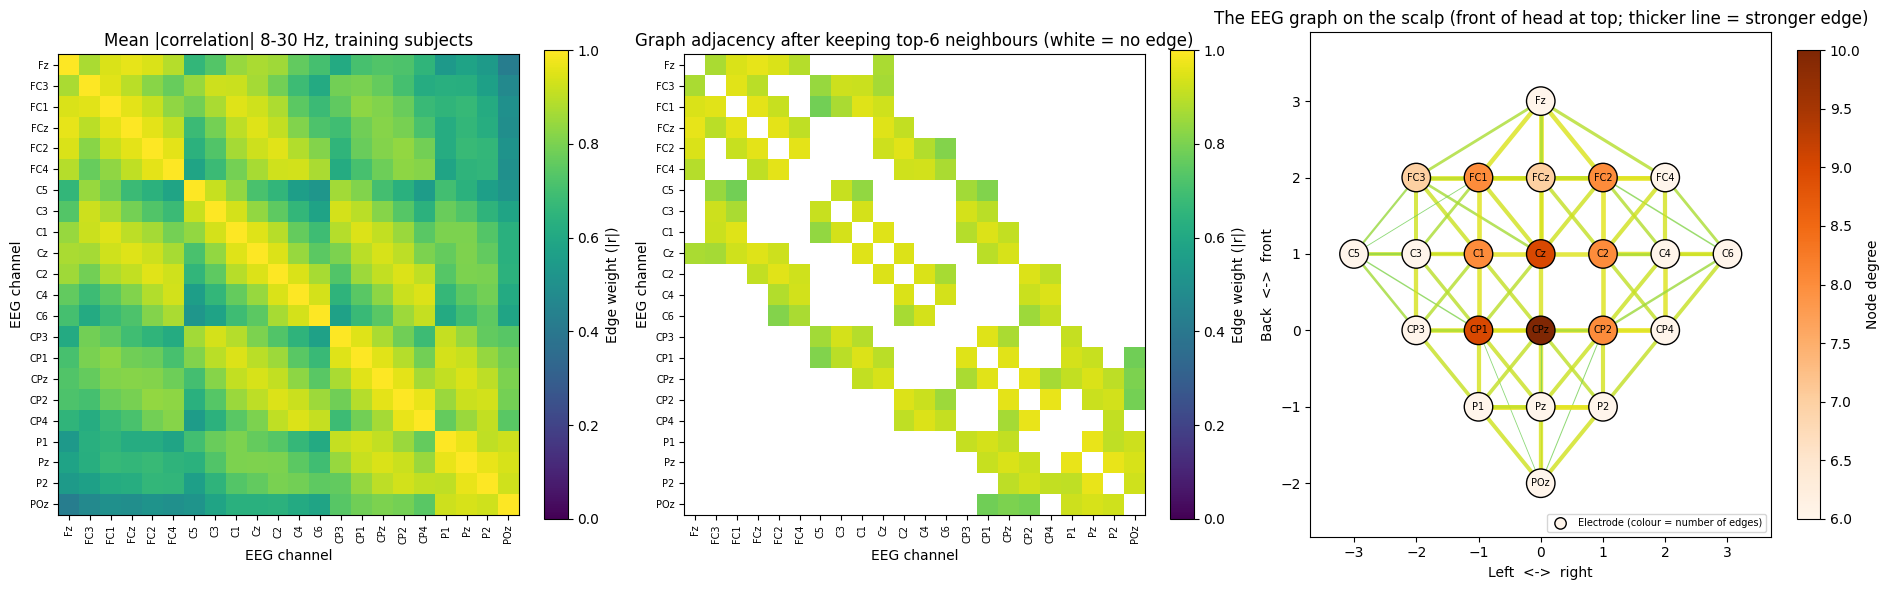

Reading: the graph has 77 edges out of 231 possible pairs. 
75% of the edges join electrodes that are direct neighbours on the scalp and 3% cross from the left to the right hemisphere. 
Strongest edge: P1-Pz (|r| = 0.97). 
Most connected electrode: CPz (10 edges); least: Fz (6 edges). 
A high share of neighbour edges means the correlation graph largely follows scalp geometry, which is what volume conduction produces; 
the long-range and cross-hemisphere edges are the part a plain distance graph would not contain.


In [39]:
# Approximate scalp layout of the 22 electrodes (nose at the top), for drawing only
POS = {"Fz": (0, 3), "FC3": (-2, 2), "FC1": (-1, 2), "FCz": (0, 2), "FC2": (1, 2), "FC4": (2, 2),
       "C5": (-3, 1), "C3": (-2, 1), "C1": (-1, 1), "Cz": (0, 1), "C2": (1, 1), "C4": (2, 1), "C6": (3, 1),
       "CP3": (-2, 0), "CP1": (-1, 0), "CPz": (0, 0), "CP2": (1, 0), "CP4": (2, 0),
       "P1": (-1, -1), "Pz": (0, -1), "P2": (1, -1), "POz": (0, -2)}
xy = np.array([POS[c] for c in ch_names], dtype=float)

A_sparse = np.zeros((N_CH, N_CH), dtype=np.float32)
A_sparse[EI_main[0], EI_main[1]] = EW_main

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
im0 = axes[0].imshow(A_train, cmap="viridis", vmin=0, vmax=1)
axes[0].set(title="Mean |correlation| 8-30 Hz, training subjects", xlabel="EEG channel", ylabel="EEG channel")
im1 = axes[1].imshow(np.ma.masked_equal(A_sparse, 0), cmap="viridis", vmin=0, vmax=1)
axes[1].set(title=f"Graph adjacency after keeping top-{K_NEIGHBORS} neighbours (white = no edge)", xlabel="EEG channel", ylabel="EEG channel")
for ax, im in [(axes[0], im0), (axes[1], im1)]:
    ax.set_xticks(range(N_CH)); ax.set_yticks(range(N_CH))
    ax.set_xticklabels(ch_names, rotation=90, fontsize=7); ax.set_yticklabels(ch_names, fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.046, label="Edge weight (|r|)")

wmin, wmax = EW_main.min(), EW_main.max()
for s, d, w in zip(EI_main[0], EI_main[1], EW_main):
    if s < d:
        axes[2].plot(xy[[s, d], 0], xy[[s, d], 1], color=plt.cm.viridis(w), lw=0.6 + 3.0 * (w - wmin) / (wmax - wmin + 1e-9), alpha=0.8, zorder=1)
deg = np.bincount(EI_main[0], minlength=N_CH)
sc = axes[2].scatter(xy[:, 0], xy[:, 1], s=420, c=deg, cmap="Oranges", edgecolors="k", zorder=2, label="Electrode (colour = number of edges)")
for (px, py), c in zip(xy, ch_names):
    axes[2].text(px, py, c, ha="center", va="center", fontsize=7, zorder=3)
fig.colorbar(sc, ax=axes[2], fraction=0.046, label="Node degree")
axes[2].set(title="The EEG graph on the scalp (front of head at top; thicker line = stronger edge)", xlabel="Left  <->  right", ylabel="Back  <->  front")
axes[2].set_xlim(-3.7, 3.7); axes[2].set_ylim(-2.7, 3.9); axes[2].legend(loc="lower right", fontsize=7, markerscale=0.4)
finish(fig, "nb2_graph_construction.png")

und = EI_main[:, EI_main[0] < EI_main[1]]
dist = np.linalg.norm(xy[und[0]] - xy[und[1]], axis=1)
cross = np.sign(xy[und[0], 0]) * np.sign(xy[und[1], 0]) < 0
i_max = int(np.argmax(EW_main))
print(f"Reading: the graph has {und.shape[1]} edges out of {N_CH * (N_CH - 1) // 2} possible pairs. "
      f"\n{(dist <= 1.5).mean():.0%} of the edges join electrodes that are direct neighbours on the scalp and {cross.mean():.0%} cross from the left to the right hemisphere. "
      f"\nStrongest edge: {ch_names[EI_main[0][i_max]]}-{ch_names[EI_main[1][i_max]]} (|r| = {EW_main[i_max]:.2f}). "
      f"\nMost connected electrode: {ch_names[int(deg.argmax())]} ({deg.max()} edges); least: {ch_names[int(deg.argmin())]} ({deg.min()} edges). "
      f"\nA high share of neighbour edges means the correlation graph largely follows scalp geometry, which is what volume conduction produces; "
      f"\nthe long-range and cross-hemisphere edges are the part a plain distance graph would not contain.")

## 7. Prepare the graph data for the GNN
Each trial becomes one PyTorch Geometric `Data` object:

- `x` — node feature matrix, shape (22, 11), standardised with training statistics
- `edge_index` — the list of connected electrode pairs, shape (2, E), both directions
- `edge_weight` — connection strength for each pair, shape (E,)
- `y` — the class of the trial (0 = left hand, 1 = right hand, 2 = both feet, 3 = tongue)

A `DataLoader` then stacks 64 trial-graphs into one large disconnected graph per batch.

In [14]:
def to_graphs(idx, Xn, ei, ew, mode):
    graphs = []
    if mode == "group":
        ei_t, ew_t = torch.from_numpy(ei).long(), torch.from_numpy(ew).float()
    for n in idx:
        if mode == "per_trial":                       # graph from this trial's own connectivity
            e, w = topk_edges(CONN[n], K_NEIGHBORS)
            ei_t, ew_t = torch.from_numpy(e).long(), torch.from_numpy(w).float()
        elif mode == "none":                          # no edges: nodes cannot exchange information
            ei_t, ew_t = torch.empty((2, 0), dtype=torch.long), torch.empty((0,), dtype=torch.float)
        graphs.append(Data(x=torch.from_numpy(Xn[n].copy()), edge_index=ei_t, edge_weight=ew_t,
                           y=torch.tensor([int(y[n])], dtype=torch.long)))
    return graphs

example = to_graphs(tr_idx[:1], Xn_main, EI_main, EW_main, "group")[0]
print("One trial as a graph:", example)
print("Nodes:", example.num_nodes, "| node features:", example.num_node_features, "| directed edges:", example.num_edges,
      "| label:", CLASS_NAMES[int(example.y)])

One trial as a graph: Data(x=[22, 11], edge_index=[2, 154], y=[1], edge_weight=[154])
Nodes: 22 | node features: 11 | directed edges: 154 | label: Tongue


## 8. (B) Architecture diagram

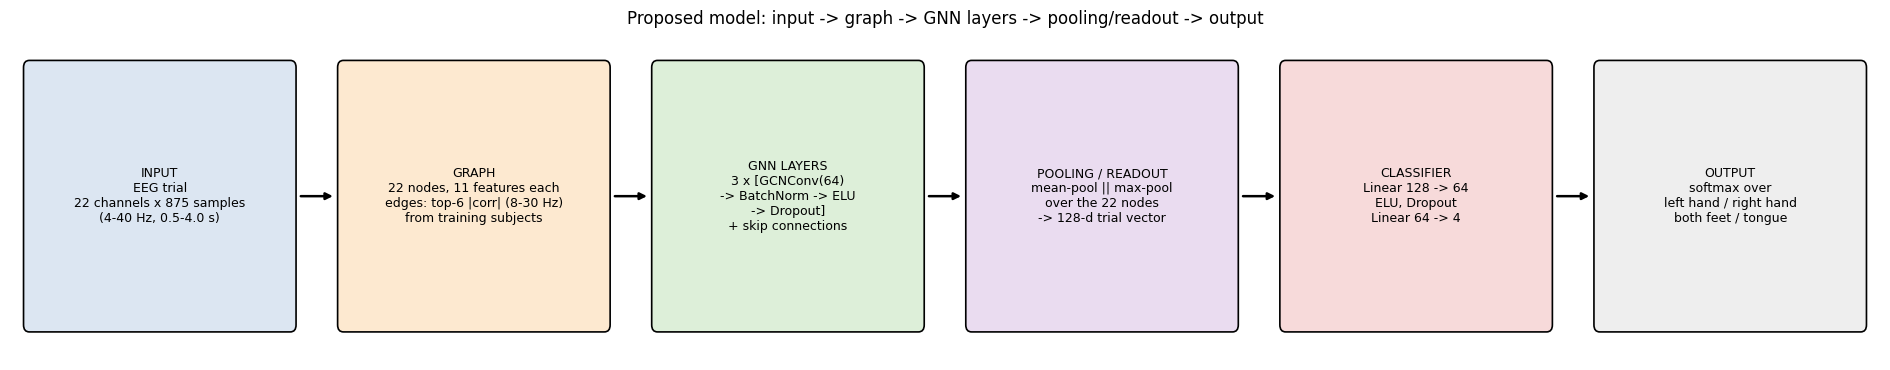

Reading: data flows left to right.
Only the green, purple and red blocks have trainable weights; the graph block is fixed once the training subjects are known.


In [40]:
from matplotlib.patches import FancyBboxPatch

boxes = [
    ("INPUT\nEEG trial\n22 channels x 875 samples\n(4-40 Hz, 0.5-4.0 s)", "#DCE6F2"),
    ("GRAPH\n22 nodes, 11 features each\nedges: top-6 |corr| (8-30 Hz)\nfrom training subjects", "#FDE9D0"),
    ("GNN LAYERS\n3 x [GCNConv(64)\n-> BatchNorm -> ELU\n-> Dropout]\n+ skip connections", "#DDEFD9"),
    ("POOLING / READOUT\nmean-pool || max-pool\nover the 22 nodes\n-> 128-d trial vector", "#EADCF0"),
    ("CLASSIFIER\nLinear 128 -> 64\nELU, Dropout\nLinear 64 -> 4", "#F7DADA"),
    ("OUTPUT\nsoftmax over\nleft hand / right hand\nboth feet / tongue", "#EEEEEE"),
]
fig, ax = plt.subplots(figsize=(19, 3.8))
w, h, gap = 2.7, 2.2, 0.55
for i, (txt, col) in enumerate(boxes):
    x0 = i * (w + gap)
    ax.add_patch(FancyBboxPatch((x0, 0), w, h, boxstyle="round,pad=0.06", fc=col, ec="k", lw=1.2))
    ax.text(x0 + w / 2, h / 2, txt, ha="center", va="center", fontsize=9)
    if i < len(boxes) - 1:
        ax.annotate("", xy=(x0 + w + gap - 0.08, h / 2), xytext=(x0 + w + 0.08, h / 2), arrowprops=dict(arrowstyle="-|>", lw=1.8, color="k"))
ax.set_xlim(-0.2, len(boxes) * (w + gap) - gap + 0.2); ax.set_ylim(-0.3, h + 0.3); ax.axis("off")
ax.set_title("Proposed model: input -> graph -> GNN layers -> pooling/readout -> output", fontsize=12)
finish(fig, "nb2_architecture.png")
print("Reading: data flows left to right.\nOnly the green, purple and red blocks have trainable weights; the graph block is fixed once the training subjects are known.")

## 8. (C) The model in plain words


**The idea.** A normal classifier receives 242 numbers in a row and has no idea that numbers 1–11 come from one electrode and 12–22 from the one next to it. The GNN is told two extra things: which numbers belong to the same electrode, and which electrodes behave alike.

**What one GCN layer does.** Every electrode looks at the electrodes it is connected to, takes a weighted average of their feature vectors (strongly correlated neighbours count more), mixes that average with its own vector, and passes the result through a small learned transformation. After one layer an electrode "knows" about its direct neighbours; after three layers, about electrodes up to three steps away. This smooths out noise on single electrodes and lets the model build regional patterns such as "mu power is lower on the left motor strip than on the right".

**Readout.** The model must give one answer per trial, not per electrode. So the 22 node vectors are summarised twice: their average (the overall state) and their element-wise maximum (the strongest local response). The two are joined into one 128-number description of the trial.

**Classifier.** Two linear layers turn that description into four scores, and softmax turns the scores into probabilities.

**Why it suits this data.** Motor imagery is spatial: left hand → right motor cortex (around C4), right hand → left (C3), feet → centre (Cz), tongue → lower lateral areas. The class is encoded in *where* power changes, relative to other places. A graph over electrodes is a direct way to give the model that "where".

**Settings**

| Setting | Value | Reason |
|---|---|---|
| GNN layer | GCNConv with edge weights | simplest message-passing layer; few parameters for 1,728 training graphs |
| Layers / hidden size | 3 / 64 | three hops cover most of the 22-node graph |
| Normalisation, activation | BatchNorm, ELU | stable training on small batches of graphs |
| Skip connections | from layer 2 on | reduces over-smoothing (all nodes becoming alike) |
| Dropout | 0.4 | strong regularisation; subjects differ a lot |
| Readout | mean ‖ max pooling | overall level plus strongest local response |
| Loss | cross-entropy, label smoothing 0.1 | labels are noisy (subjects do not always perform the imagery) |
| Optimiser | AdamW, lr 1e-3, weight decay 5e-3 | standard choice |
| Batch size / max epochs | 64 / 150 | — |
| Early stopping | validation loss on A07, patience 25 | test subjects are never used to stop training |
| Seeds | 42, 43, 44 | small data → report mean ± std, not one lucky run |
| Graph | top-6 neighbours, mean abs. correlation 8–30 Hz, training subjects | section 6 |

In [16]:
CFG = dict(hidden=64, n_layers=3, dropout=0.4, lr=1e-3, weight_decay=5e-3, batch_size=64,
           max_epochs=150, patience=25, label_smoothing=0.1)
SEEDS = [42, 43, 44]
GRAPH_MODE = "group"          # "group" (proposed) | "per_trial" | "none"

In [17]:
class EEGGCN(nn.Module):
    def __init__(self, in_dim, hidden=64, n_layers=3, n_cls=4, dropout=0.4):
        super().__init__()
        self.in_norm = nn.BatchNorm1d(in_dim)
        self.convs, self.norms = nn.ModuleList(), nn.ModuleList()
        for l in range(n_layers):
            self.convs.append(GCNConv(in_dim if l == 0 else hidden, hidden))
            self.norms.append(nn.BatchNorm1d(hidden))
        self.dropout = dropout
        self.head = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ELU(), nn.Dropout(dropout), nn.Linear(hidden, n_cls))

    def forward(self, x, edge_index, edge_weight, batch):
        h = self.in_norm(x)
        for l, (conv, norm) in enumerate(zip(self.convs, self.norms)):
            h_new = F.elu(norm(conv(h, edge_index, edge_weight)))          # message passing over the EEG graph
            h_new = F.dropout(h_new, p=self.dropout, training=self.training)
            h = h_new if l == 0 else h + h_new                              # skip connection
        g = torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1)   # readout: one vector per trial
        return self.head(g)

_m = EEGGCN(N_FEAT, CFG["hidden"], CFG["n_layers"], N_CLASSES, CFG["dropout"])
print(_m)
print("Trainable parameters:", sum(p.numel() for p in _m.parameters()))

EEGGCN(
  (in_norm): BatchNorm1d(11, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (convs): ModuleList(
    (0): GCNConv(11, 64)
    (1-2): 2 x GCNConv(64, 64)
  )
  (norms): ModuleList(
    (0-2): 3 x BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ELU(alpha=1.0)
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=64, out_features=4, bias=True)
  )
)
Trainable parameters: 18010


## 9. Training
One function does a complete run: fit scaler and graph on the training subjects, build the graphs, train with early stopping on the validation subject, predict the test subjects once.

In [18]:
def gnn_pass(model, loader, crit, opt=None):
    model.train(opt is not None)
    tot, n, probs = 0.0, 0, []
    with torch.set_grad_enabled(opt is not None):
        for b in loader:
            b = b.to(DEVICE)
            out = model(b.x, b.edge_index, b.edge_weight, b.batch)
            loss = crit(out, b.y)
            if opt is not None:
                opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * b.num_graphs; n += b.num_graphs
            probs.append(F.softmax(out, dim=1).detach().cpu().numpy())
    return tot / n, np.concatenate(probs)

def train_gnn(train_idx, val_idx, test_idx, mode=GRAPH_MODE, seed=SEED):
    set_seed(seed)
    Xn, ei, ew = fold_arrays(train_idx, mode)                       # fitted on train_idx only
    dl_tr = DataLoader(to_graphs(train_idx, Xn, ei, ew, mode), batch_size=CFG["batch_size"], shuffle=True)
    dl_va = DataLoader(to_graphs(val_idx, Xn, ei, ew, mode), batch_size=256, shuffle=False)
    dl_te = DataLoader(to_graphs(test_idx, Xn, ei, ew, mode), batch_size=256, shuffle=False)

    model = EEGGCN(N_FEAT, CFG["hidden"], CFG["n_layers"], N_CLASSES, CFG["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])

    hist = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_val, best_state, wait = np.inf, None, 0
    t0 = time.time()
    for ep in range(CFG["max_epochs"]):
        tl, _ = gnn_pass(model, dl_tr, crit, opt)
        vl, vp = gnn_pass(model, dl_va, crit)
        hist["train_loss"].append(tl); hist["val_loss"].append(vl)
        hist["val_f1"].append(f1_score(y[val_idx], vp.argmax(1), average="macro"))
        if vl < best_val - 1e-4:
            best_val, best_state, wait = vl, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= CFG["patience"]:
                break
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    t0 = time.time(); _, proba_test = gnn_pass(model, dl_te, crit); infer_ms = 1000 * (time.time() - t0) / len(test_idx)
    return {"proba_test": proba_test, "hist": hist, "val_loss": best_val, "best_epoch": int(np.argmin(hist["val_loss"])) + 1,
            "train_time": train_time, "infer_ms": infer_ms, "n_params": sum(p.numel() for p in model.parameters()), "model": model}

In [19]:
runs = {}
for s in SEEDS:
    runs[s] = train_gnn(tr_idx, va_idx, te_idx, mode=GRAPH_MODE, seed=s)
    r = runs[s]
    print(f"seed {s}: {len(r['hist']['val_loss'])} epochs (best {r['best_epoch']}), {r['train_time']:.1f}s, val loss {r['val_loss']:.3f}, "
          f"test macro-F1 {f1_score(y_test, r['proba_test'].argmax(1), average='macro'):.3f}")

seed_df = pd.DataFrame([{"Seed": s, **compute_metrics(y_test, r["proba_test"]), "Val loss": r["val_loss"],
                         "Best epoch": r["best_epoch"], "Train time (s)": r["train_time"]} for s, r in runs.items()]).set_index("Seed")
best_seed = int(seed_df["Val loss"].idxmin())            # chosen on VALIDATION, not on test
proba_gnn, hist, best_epoch = runs[best_seed]["proba_test"], runs[best_seed]["hist"], runs[best_seed]["best_epoch"]
gnn_time, gnn_infer_ms, n_params = float(seed_df["Train time (s)"].mean()), runs[best_seed]["infer_ms"], runs[best_seed]["n_params"]
torch.save(runs[best_seed]["model"].state_dict(), os.path.join(RESULTS_DIR, "gnn_best_model.pt"))

seed 42: 44 epochs (best 19), 15.6s, val loss 1.370, test macro-F1 0.138
seed 43: 78 epochs (best 53), 28.3s, val loss 1.357, test macro-F1 0.159
seed 44: 26 epochs (best 1), 9.3s, val loss 1.358, test macro-F1 0.178


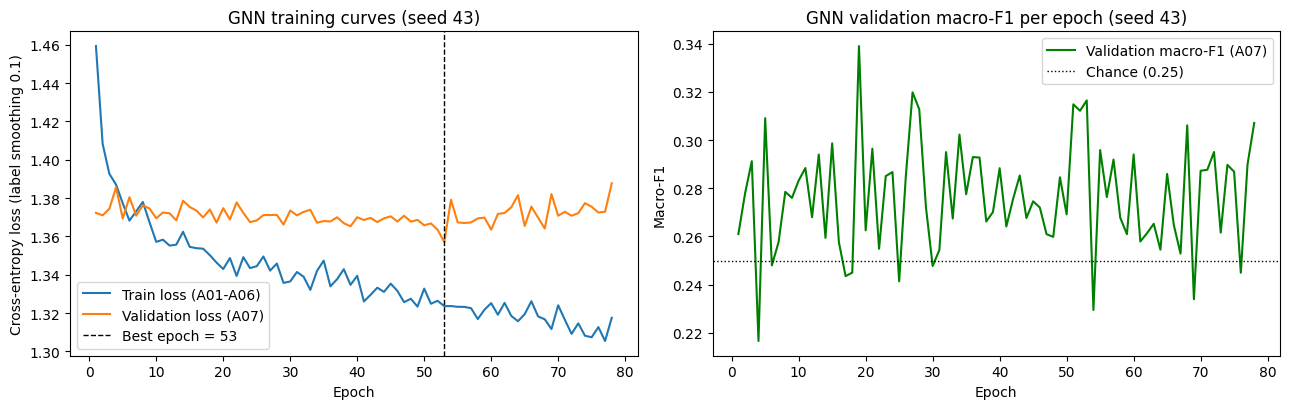

Reading: training ran 78 epochs and the weights from epoch 53 were kept (lowest validation loss). 
Validation minus train loss at that epoch = 0.03. 
The two curves stay close, so the model is not strongly over-fitting the training subjects; capacity or features, not regularisation, are the limit. 
Validation macro-F1 peaks at 0.339.


In [43]:
ep_ax = np.arange(1, len(hist["val_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(ep_ax, hist["train_loss"], label="Train loss (A01-A06)")
axes[0].plot(ep_ax, hist["val_loss"], label="Validation loss (A07)")
axes[0].axvline(best_epoch, color="k", ls="--", lw=1, label=f"Best epoch = {best_epoch}")
axes[0].set(title=f"GNN training curves (seed {best_seed})", xlabel="Epoch", ylabel="Cross-entropy loss (label smoothing 0.1)"); axes[0].legend()
axes[1].plot(ep_ax, hist["val_f1"], color="green", label="Validation macro-F1 (A07)")
axes[1].axhline(0.25, color="k", ls=":", lw=1, label="Chance (0.25)")
axes[1].set(title=f"GNN validation macro-F1 per epoch (seed {best_seed})", xlabel="Epoch", ylabel="Macro-F1"); axes[1].legend()
finish(fig, "nb2_gnn_training.png")
gap = hist["val_loss"][best_epoch - 1] - hist["train_loss"][best_epoch - 1]
print(f"Reading: training ran {len(ep_ax)} epochs and the weights from epoch {best_epoch} were kept (lowest validation loss). "
      f"\nValidation minus train loss at that epoch = {gap:.2f}. "
      + ("\nThe validation loss stops improving while the train loss keeps falling: the model starts learning details of the six training people that do not transfer to a new person. Early stopping cuts training there."
         if gap > 0.15 else "\nThe two curves stay close, so the model is not strongly over-fitting the training subjects; capacity or features, not regularisation, are the limit.")
      + f" \nValidation macro-F1 peaks at {max(hist['val_f1']):.3f}.")

## 10. First results on the held-out test subjects (A08, A09)
### 10.1 Full metric set, per seed

In [44]:
display(seed_df[METRIC_COLS + ["Best epoch", "Train time (s)"]].round(3))
gnn_mean, gnn_std = seed_df[METRIC_COLS].mean(), seed_df[METRIC_COLS].std()
display(pd.DataFrame({"mean": gnn_mean, "std": gnn_std}).T.round(3))
print(f"Reading: over {len(seed_df)} seeds the GNN reaches macro-F1 = {gnn_mean['F1 (macro)']:.3f} +/- {gnn_std['F1 (macro)']:.3f}, "
      f"accuracy = {gnn_mean['Accuracy']:.3f} +/- {gnn_std['Accuracy']:.3f}, macro ROC-AUC = {gnn_mean['ROC-AUC (macro OvR)']:.3f} (chance: 0.25 / 0.25 / 0.50). "
      f"\nThe seed-to-seed std is the noise floor: differences between models smaller than about {2 * gnn_std['F1 (macro)']:.3f} macro-F1 should not be called a win. "
      f"\nMacro and weighted F1 differ by {abs(gnn_mean['F1 (macro)'] - gnn_mean['F1 (weighted)']):.3f} (classes are balanced).")

,Accuracy,Balanced acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AUC (macro OvR),Best epoch,Train time (s)
Seed,,,,,,,,,,,,
42,0.262,0.262,0.379,0.262,0.138,0.379,0.262,0.138,0.625,0.361,19,15.558
43,0.276,0.276,0.344,0.276,0.159,0.344,0.276,0.159,0.614,0.374,53,28.325
44,0.271,0.271,0.189,0.271,0.178,0.189,0.271,0.178,0.602,0.352,1,9.258


,Accuracy,Balanced acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AUC (macro OvR)
mean,0.270,0.270,0.304,0.270,0.159,0.304,0.270,0.159,0.614,0.362
std,0.007,0.007,0.101,0.007,0.020,0.101,0.007,0.020,0.011,0.011


Reading: over 3 seeds the GNN reaches macro-F1 = 0.159 +/- 0.020, accuracy = 0.270 +/- 0.007, macro ROC-AUC = 0.614 (chance: 0.25 / 0.25 / 0.50). 
The seed-to-seed std is the noise floor: differences between models smaller than about 0.040 macro-F1 should not be called a win. 
Macro and weighted F1 differ by 0.000 (classes are balanced).


### 10.2 Per-class report and confusion matrix (run chosen by validation loss)

,precision,recall,f1-score,ROC-AUC,support
class,,,,,
Left hand,0.714,0.069,0.127,0.639,144
Right hand,0.000,0.000,0.000,0.542,144
Both feet,0.400,0.056,0.098,0.574,144
Tongue,0.260,0.979,0.411,0.700,144
macro avg,0.344,0.276,0.159,0.614,576
weighted avg,0.344,0.276,0.159,0.614,576


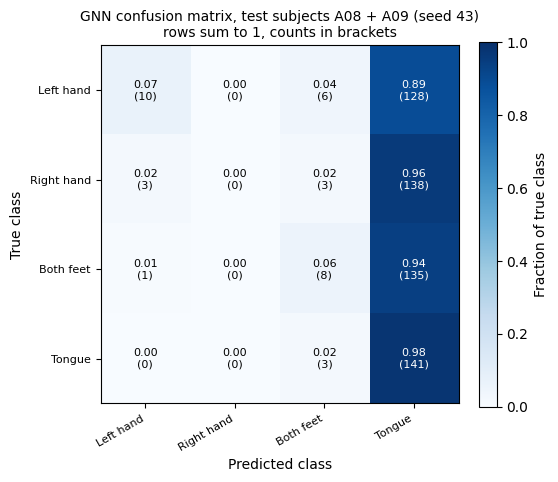

Reading (GNN): best-recognised class = Tongue (recall 0.98); weakest = Right hand (recall 0.00); most common mistake = true 'Right hand' predicted as 'Tongue' (96% of those trials).
Left/right hand confusion: 0% of left-hand trials are called right hand and 2% the other way round. 
These two classes differ only by hemisphere, so this pair shows whether the model uses the left-right layout of the graph.


In [45]:
pred_gnn = proba_gnn.argmax(1)
pc_gnn = per_class_table(y_test, proba_gnn)
display(pc_gnn.round(3))

fig, ax = plt.subplots(figsize=(5.6, 5))
im = plot_confusion(ax, y_test, pred_gnn, f"GNN confusion matrix, test subjects A08 + A09 (seed {best_seed})\nrows sum to 1, counts in brackets")
fig.colorbar(im, ax=ax, fraction=0.046, label="Fraction of true class")
finish(fig, "nb2_gnn_confusion.png")
read_confusion(y_test, pred_gnn, "GNN")
lr_conf = confusion_matrix(y_test, pred_gnn, labels=np.arange(N_CLASSES), normalize="true")
print(f"Left/right hand confusion: {lr_conf[0, 1]:.0%} of left-hand trials are called right hand and {lr_conf[1, 0]:.0%} the other way round. "
      f"\nThese two classes differ only by hemisphere, so this pair shows whether the model uses the left-right layout of the graph.")

### 10.3 ROC and precision–recall curves (one-vs-rest)

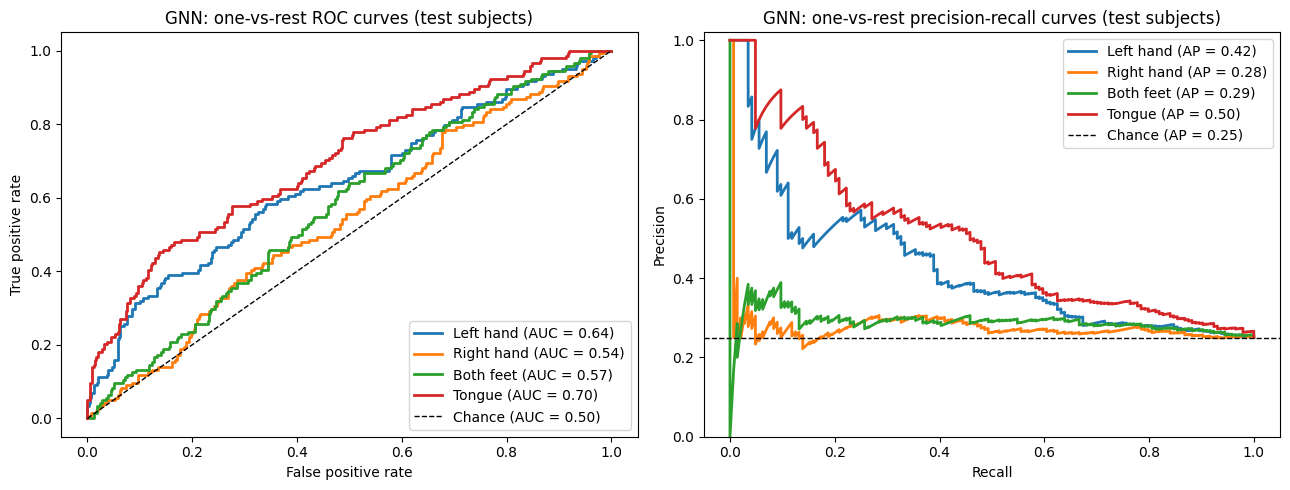

Reading (GNN): every curve above the dashed line means the model ranks that class better than chance. Easiest class to separate = Tongue (AUC 0.70, AP 0.50); hardest = Right hand (AUC 0.54, AP 0.28). Macro AUC = 0.614; chance is 0.50 for AUC and 0.25 for AP.


In [23]:
plot_ovr_curves(y_test, proba_gnn, "GNN", "nb2_gnn_roc_pr.png")

### 10.4 Per test subject

In [24]:
rows = []
for s in TEST_SUBJECTS:
    m = subjects[te_idx] == s
    rows.append({"Test subject": s, "Trials": int(m.sum()), "Accuracy": accuracy_score(y_test[m], pred_gnn[m]),
                 "F1 (macro)": f1_score(y_test[m], pred_gnn[m], average="macro"),
                 **{f"Recall {CLASS_NAMES[c]}": recall_score(y_test[m], pred_gnn[m], labels=[c], average="macro", zero_division=0) for c in range(N_CLASSES)}})
gnn_subj_df = pd.DataFrame(rows).set_index("Test subject")
display(gnn_subj_df.round(3))
print(f"Reading: macro-F1 is " + " and ".join(f"{v:.3f} on {s}" for s, v in gnn_subj_df["F1 (macro)"].items()) +
      f". A gap of {abs(gnn_subj_df['F1 (macro)'].diff().iloc[-1]):.3f} between two people shows how much the result depends on who is tested.")

,Trials,Accuracy,F1 (macro),Recall Left hand,Recall Right hand,Recall Both feet,Recall Tongue
Test subject,,,,,,,
A08,288,0.260,0.121,0.000,0.0,0.042,1.000
A09,288,0.292,0.191,0.139,0.0,0.069,0.958


Reading: macro-F1 is 0.121 on A08 and 0.191 on A09. A gap of 0.070 between two people shows how much the result depends on who is tested.


## 11. Comparison with the baselines
Same test subjects, same metrics, same features. The GNN row is the mean over the three seeds; the baselines are deterministic single runs from Notebook 1.

In [46]:
base_path = os.path.join(RESULTS_DIR, "baseline_results.csv")
assert os.path.exists(base_path), "baseline_results.csv not found: run Notebook 1 (ML baselines) first."
base_df = pd.read_csv(base_path, index_col=0)

GNN_NAME = "GNN (proposed)"
gnn_row = {**gnn_mean.to_dict(), "Train time (s)": gnn_time, "Inference (ms/trial)": gnn_infer_ms}
cmp_cols = METRIC_COLS + ["Train time (s)", "Inference (ms/trial)"]
cmp_df = pd.concat([base_df[cmp_cols], pd.DataFrame([gnn_row], index=[GNN_NAME])[cmp_cols]]).astype(float)
cmp_df = cmp_df.sort_values("F1 (macro)", ascending=False)
cmp_df.insert(0, "Rank", range(1, len(cmp_df) + 1))
cmp_df.index.name = "Model"
display(cmp_df.round(3))

BEST_BASELINE = base_df["F1 (macro)"].astype(float).idxmax()
bb = base_df.loc[BEST_BASELINE]
d_f1 = gnn_mean["F1 (macro)"] - float(bb["F1 (macro)"])
d_auc = gnn_mean["ROC-AUC (macro OvR)"] - float(bb["ROC-AUC (macro OvR)"])
noise = 2 * gnn_std["F1 (macro)"]
if d_f1 > noise:
    verdict = "the GNN beats the best baseline by more than the seed noise"
elif d_f1 >= -noise:
    verdict = "the GNN and the best baseline are level: the difference is within the seed noise, so neither can be called better yet"
else:
    verdict = "the GNN does NOT beat the best baseline in this first version"
print(f"Baseline to beat: {BEST_BASELINE} (macro-F1 {float(bb['F1 (macro)']):.3f}, macro AUC {float(bb['ROC-AUC (macro OvR)']):.3f}, train {float(bb['Train time (s)']):.2f}s).")
print(f"GNN: macro-F1 {gnn_mean['F1 (macro)']:.3f} +/- {gnn_std['F1 (macro)']:.3f}, macro AUC {gnn_mean['ROC-AUC (macro OvR)']:.3f}, train {gnn_time:.1f}s, rank {int(cmp_df.loc[GNN_NAME, 'Rank'])} of {len(cmp_df)}.")
print(f"Reading: {verdict} (macro-F1 difference {d_f1:+.3f}, noise band +/- {noise:.3f}; macro AUC difference {d_auc:+.3f}). "
      f"\nThe GNN has {n_params:,} parameters and takes {gnn_time / max(float(bb['Train time (s)']), 1e-9):.1f}x the training time of {BEST_BASELINE}.")

,Rank,Accuracy,Balanced acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AUC (macro OvR),Train time (s),Inference (ms/trial)
Model,,,,,,,,,,,,,
Decision Tree,1,0.333,0.333,0.329,0.333,0.272,0.329,0.333,0.272,0.548,0.291,0.445,0.006
XGBoost,2,0.333,0.333,0.516,0.333,0.264,0.516,0.333,0.264,0.643,0.380,1.175,0.020
LightGBM,3,0.328,0.328,0.423,0.328,0.257,0.423,0.328,0.257,0.626,0.370,1.090,0.046
Gradient Boosting,4,0.293,0.293,0.330,0.293,0.247,0.330,0.293,0.247,0.588,0.315,5.176,0.025
Logistic Regression,5,0.312,0.312,0.457,0.312,0.232,0.457,0.312,0.232,0.682,0.420,0.125,0.008
k-NN,6,0.293,0.293,0.337,0.293,0.198,0.337,0.293,0.198,0.601,0.335,0.043,0.043
MLP,7,0.292,0.292,0.452,0.292,0.196,0.452,0.292,0.196,0.685,0.432,1.140,0.015
Random Forest,8,0.278,0.278,0.315,0.278,0.175,0.315,0.278,0.175,0.580,0.308,13.630,0.356
GNN (proposed),9,0.270,0.270,0.304,0.270,0.159,0.304,0.270,0.159,0.614,0.362,17.714,0.053


Baseline to beat: Decision Tree (macro-F1 0.272, macro AUC 0.548, train 0.44s).
GNN: macro-F1 0.159 +/- 0.020, macro AUC 0.614, train 17.7s, rank 9 of 11.
Reading: the GNN does NOT beat the best baseline in this first version (macro-F1 difference -0.114, noise band +/- 0.040; macro AUC difference +0.065). 
The GNN has 18,010 parameters and takes 39.8x the training time of Decision Tree.


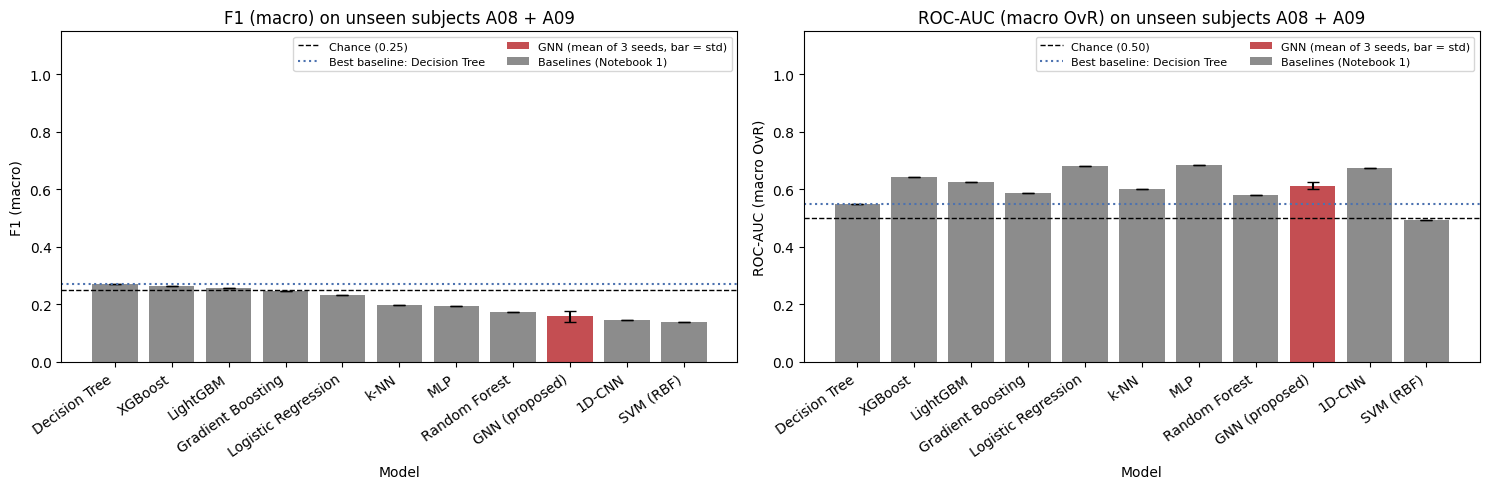

Reading: the red bar is the GNN, the dotted blue line is the score it has to pass. It is below that line for macro-F1 and above it for ROC-AUC.


In [26]:
order = cmp_df.index.tolist()
colors = ["#C44E52" if m == GNN_NAME else "#8C8C8C" for m in order]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col, chance in [(axes[0], "F1 (macro)", 0.25), (axes[1], "ROC-AUC (macro OvR)", 0.50)]:
    err = [gnn_std[col] if m == GNN_NAME else 0 for m in order]
    ax.bar(order, cmp_df[col], yerr=err, capsize=4, color=colors)
    ax.bar([0], [0], color="#C44E52", label="GNN (mean of 3 seeds, bar = std)"); ax.bar([0], [0], color="#8C8C8C", label="Baselines (Notebook 1)")
    ax.axhline(chance, color="k", ls="--", lw=1, label=f"Chance ({chance:.2f})")
    ax.axhline(float(bb[col]), color="#4C72B0", ls=":", lw=1.5, label=f"Best baseline: {BEST_BASELINE}")
    ax.set(title=f"{col} on unseen subjects A08 + A09", xlabel="Model", ylabel=col, ylim=(0, 1.15))
    ax.tick_params(axis="x", rotation=35); plt.setp(ax.get_xticklabels(), ha="right"); ax.legend(fontsize=8, ncol=2, loc="upper right")
finish(fig, "nb2_gnn_vs_baselines.png")
print(f"Reading: the red bar is the GNN, the dotted blue line is the score it has to pass. "
      f"It is {'above' if d_f1 > 0 else 'below'} that line for macro-F1 and {'above' if d_auc > 0 else 'below'} it for ROC-AUC.")

In [27]:
rec_path = os.path.join(RESULTS_DIR, "baseline_per_class_recall.csv")
if os.path.exists(rec_path):
    brec = pd.read_csv(rec_path, index_col=0).loc[BEST_BASELINE]
    grec = pc_gnn.loc[CLASS_NAMES, "recall"]
    rc_df = pd.DataFrame({f"{BEST_BASELINE} recall": brec[CLASS_NAMES].astype(float).values, f"GNN recall (seed {best_seed})": grec.values}, index=CLASS_NAMES)
    rc_df["GNN - baseline"] = rc_df.iloc[:, 1] - rc_df.iloc[:, 0]
    display(rc_df.round(3))
    print(f"Reading: per class, the GNN gains most on {rc_df['GNN - baseline'].idxmax()} ({rc_df['GNN - baseline'].max():+.3f} recall) "
          f"and loses most on {rc_df['GNN - baseline'].idxmin()} ({rc_df['GNN - baseline'].min():+.3f}). "
          f"An overall score can hide such a trade between classes.")

,Decision Tree recall,GNN recall (seed 43),GNN - baseline
Left hand,0.243,0.069,-0.174
Right hand,0.125,0.000,-0.125
Both feet,0.083,0.056,-0.028
Tongue,0.882,0.979,0.097


Reading: per class, the GNN gains most on Tongue (+0.097 recall) and loses most on Left hand (-0.174). An overall score can hide such a trade between classes.


## 12. Does the graph help? (ablation)
Three versions of the same network, same seeds, same data:

- **Group graph (proposed)** — one graph from the training subjects' mean connectivity
- **Per-trial graph** — every trial uses its own correlation matrix to pick its edges
- **No edges** — electrodes cannot exchange information; the model reduces to the same small network applied to each electrode, then pooling

If "no edges" scores the same as the proposed model, the connections are not contributing and the gain (if any) comes from the per-electrode weight sharing alone.

In [28]:
abl_runs = {"group": [runs[s]["proba_test"] for s in SEEDS] if GRAPH_MODE == "group" else None}
for mode in ["group", "per_trial", "none"]:
    if abl_runs.get(mode) is None:
        abl_runs[mode] = [train_gnn(tr_idx, va_idx, te_idx, mode=mode, seed=s)["proba_test"] for s in SEEDS]
    print("ablation done:", mode)

LABELS = {"group": "Group graph (proposed)", "per_trial": "Per-trial graph", "none": "No edges"}
rows = []
for mode, plist in abl_runs.items():
    ms = pd.DataFrame([compute_metrics(y_test, p) for p in plist])
    rows.append({"Graph": LABELS[mode], "F1 (macro) mean": ms["F1 (macro)"].mean(), "F1 (macro) std": ms["F1 (macro)"].std(),
                 "Accuracy mean": ms["Accuracy"].mean(), "ROC-AUC mean": ms["ROC-AUC (macro OvR)"].mean()})
ablation_df = pd.DataFrame(rows).set_index("Graph")

ablation done: group
ablation done: per_trial
ablation done: none


,F1 (macro) mean,F1 (macro) std,Accuracy mean,ROC-AUC mean
Graph,,,,
Group graph (proposed),0.159,0.020,0.270,0.614
Per-trial graph,0.157,0.017,0.270,0.614
No edges,0.125,0.018,0.258,0.629


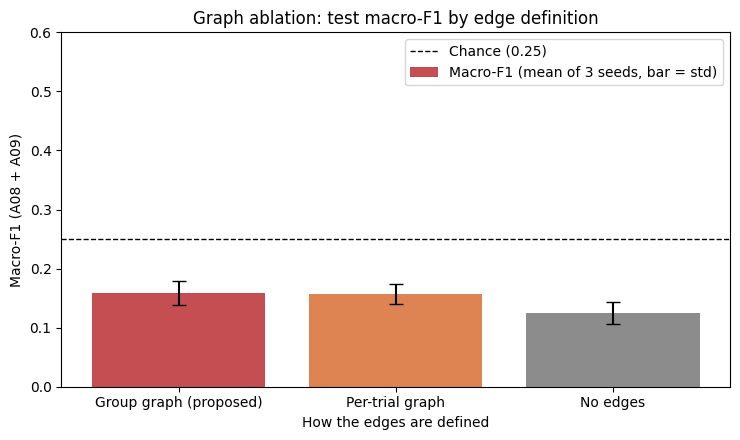

Reading: best variant = Group graph (proposed). Group graph minus no-edges = +0.034 macro-F1 (combined seed std 0.038). The no-edge model is within noise of, or better than, the graph model: in this first version message passing over the correlation graph is not yet the source of the score. Honest conclusion: the graph is not helping yet; candidates to try next are fewer neighbours, a phase-based measure (PLV), or separate graphs per frequency band.


In [29]:
display(ablation_df.round(3))
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(ablation_df.index, ablation_df["F1 (macro) mean"], yerr=ablation_df["F1 (macro) std"], capsize=5,
       color=["#C44E52", "#DD8452", "#8C8C8C"], label="Macro-F1 (mean of 3 seeds, bar = std)")
ax.axhline(0.25, color="k", ls="--", lw=1, label="Chance (0.25)")
ax.set(title="Graph ablation: test macro-F1 by edge definition", xlabel="How the edges are defined", ylabel="Macro-F1 (A08 + A09)",
       ylim=(0, max(0.6, ablation_df["F1 (macro) mean"].max() + 0.15))); ax.legend()
finish(fig, "nb2_graph_ablation.png")

g, n_ = ablation_df.loc["Group graph (proposed)"], ablation_df.loc["No edges"]
diff = g["F1 (macro) mean"] - n_["F1 (macro) mean"]; band = g["F1 (macro) std"] + n_["F1 (macro) std"]
print(f"Reading: best variant = {ablation_df['F1 (macro) mean'].idxmax()}. Group graph minus no-edges = {diff:+.3f} macro-F1 (combined seed std {band:.3f}). "
      + ("The connections add information beyond what each electrode carries alone." if diff > band else
         "The no-edge model is within noise of, or better than, the graph model: in this first version message passing over the correlation graph is not yet the source of the score. "
         "Honest conclusion: the graph is not helping yet; candidates to try next are fewer neighbours, a phase-based measure (PLV), or separate graphs per frequency band."))

## 13. Leave-one-subject-out (LOSO)
Each subject is the test person once. For every fold the scaler **and the graph** are rebuilt from that fold's training subjects. The next subject in order serves as validation for early stopping, so the GNN trains on 7 people where the Notebook 1 baselines trained on 8.

Set `RUN_LOSO = False` to skip (9 extra training runs).

In [30]:
RUN_LOSO = True
all_subjects = sorted(set(subjects))
rows = []
if RUN_LOSO:
    for i, s in enumerate(all_subjects):
        v = all_subjects[(i + 1) % len(all_subjects)]
        te, va = np.where(subjects == s)[0], np.where(subjects == v)[0]
        tr = np.where((subjects != s) & (subjects != v))[0]
        r = train_gnn(tr, va, te, mode=GRAPH_MODE, seed=SEED)
        p = r["proba_test"].argmax(1)
        rows.append({"Test subject": s, "Validation subject": v, "Accuracy": accuracy_score(y[te], p),
                     "F1 (macro)": f1_score(y[te], p, average="macro"), "Best epoch": r["best_epoch"]})
        print(f"LOSO test {s} (val {v}): macro-F1 {rows[-1]['F1 (macro)']:.3f}")
gnn_loso_df = pd.DataFrame(rows)

LOSO test A01 (val A02): macro-F1 0.225
LOSO test A02 (val A03): macro-F1 0.211
LOSO test A03 (val A04): macro-F1 0.199
LOSO test A04 (val A05): macro-F1 0.249
LOSO test A05 (val A06): macro-F1 0.148
LOSO test A06 (val A07): macro-F1 0.228
LOSO test A07 (val A08): macro-F1 0.180
LOSO test A08 (val A09): macro-F1 0.125
LOSO test A09 (val A01): macro-F1 0.114


,Test subject,Validation subject,Accuracy,F1 (macro),Best epoch
0,A01,A02,0.264,0.225,1
1,A02,A03,0.264,0.211,8
2,A03,A04,0.295,0.199,6
3,A04,A05,0.278,0.249,1
4,A05,A06,0.250,0.148,9
5,A06,A07,0.264,0.228,25
6,A07,A08,0.236,0.180,2
7,A08,A09,0.226,0.125,1
8,A09,A01,0.253,0.114,24


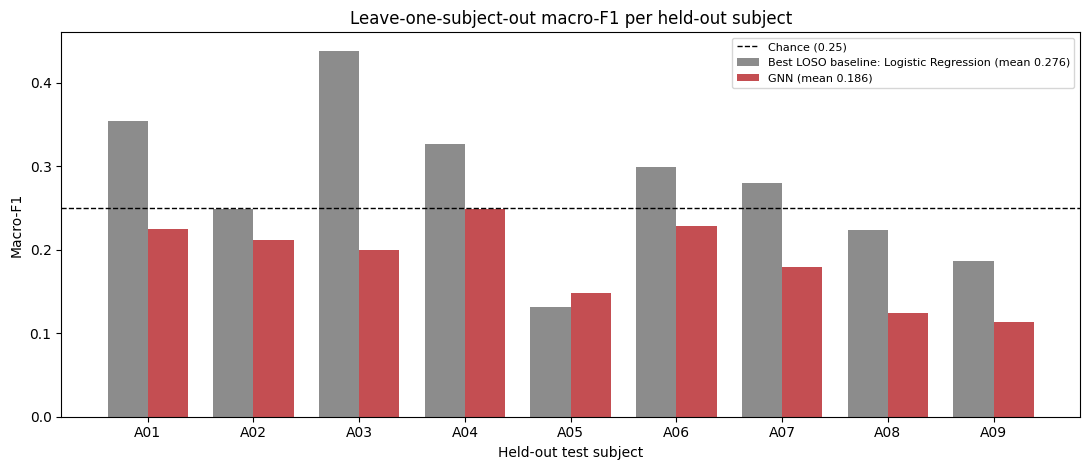

Reading: GNN LOSO macro-F1 = 0.186 +/- 0.048 over 9 subjects. Easiest person: A04 (0.249); hardest: A09 (0.114); 0 of 9 are clearly above chance. Against Logistic Regression (0.276 +/- 0.092) the GNN is better on 1 of 9 subjects; mean difference -0.090. With 9 subjects, a difference much smaller than the std across subjects is not reliable evidence.


In [31]:
if len(gnn_loso_df):
    display(gnn_loso_df.round(3))
    gm, gs = gnn_loso_df["F1 (macro)"].mean(), gnn_loso_df["F1 (macro)"].std()
    fig, ax = plt.subplots(figsize=(11, 4.8))
    xs = np.arange(len(gnn_loso_df)); wbar = 0.38
    loso_path = os.path.join(RESULTS_DIR, "baseline_loso.csv")
    msg = ""
    if os.path.exists(loso_path):
        bl = pd.read_csv(loso_path)
        best_lo = bl.groupby("Model")["F1 (macro)"].mean().idxmax()
        bvals = bl[bl.Model == best_lo].set_index("Test subject").loc[gnn_loso_df["Test subject"], "F1 (macro)"].values
        ax.bar(xs - wbar / 2, bvals, wbar, color="#8C8C8C", label=f"Best LOSO baseline: {best_lo} (mean {bvals.mean():.3f})")
        ax.bar(xs + wbar / 2, gnn_loso_df["F1 (macro)"], wbar, color="#C44E52", label=f"GNN (mean {gm:.3f})")
        wins = int((gnn_loso_df["F1 (macro)"].values > bvals).sum())
        msg = (f" Against {best_lo} ({bvals.mean():.3f} +/- {bvals.std(ddof=1):.3f}) the GNN is better on {wins} of {len(bvals)} subjects; "
               f"mean difference {gm - bvals.mean():+.3f}. With 9 subjects, a difference much smaller than the std across subjects is not reliable evidence.")
    else:
        ax.bar(xs, gnn_loso_df["F1 (macro)"], color="#C44E52", label=f"GNN (mean {gm:.3f})")
    ax.axhline(0.25, color="k", ls="--", lw=1, label="Chance (0.25)")
    ax.set_xticks(xs); ax.set_xticklabels(gnn_loso_df["Test subject"])
    ax.set(title="Leave-one-subject-out macro-F1 per held-out subject", xlabel="Held-out test subject", ylabel="Macro-F1"); ax.legend(fontsize=8)
    finish(fig, "nb2_loso.png")
    hi, lo = gnn_loso_df.loc[gnn_loso_df["F1 (macro)"].idxmax()], gnn_loso_df.loc[gnn_loso_df["F1 (macro)"].idxmin()]
    print(f"Reading: GNN LOSO macro-F1 = {gm:.3f} +/- {gs:.3f} over {len(gnn_loso_df)} subjects. Easiest person: {hi['Test subject']} ({hi['F1 (macro)']:.3f}); "
          f"hardest: {lo['Test subject']} ({lo['F1 (macro)']:.3f}); {(gnn_loso_df['F1 (macro)'] > 0.30).sum()} of {len(gnn_loso_df)} are clearly above chance." + msg)
else:
    print("LOSO skipped (RUN_LOSO = False).")

## 14. Save results

In [32]:
cmp_df.to_csv(os.path.join(RESULTS_DIR, "task2_comparison_table.csv"))
seed_df.to_csv(os.path.join(RESULTS_DIR, "gnn_seed_results.csv"))
pc_gnn.to_csv(os.path.join(RESULTS_DIR, "gnn_per_class_report.csv"))
ablation_df.to_csv(os.path.join(RESULTS_DIR, "gnn_graph_ablation.csv"))
if len(gnn_loso_df):
    gnn_loso_df.to_csv(os.path.join(RESULTS_DIR, "gnn_loso.csv"), index=False)
json.dump({"config": CFG, "seeds": SEEDS, "graph_mode": GRAPH_MODE, "k_neighbors": K_NEIGHBORS, "n_params": int(n_params),
           "node_features": FEAT_NAMES, "train_subjects": TRAIN_SUBJECTS, "val_subjects": VAL_SUBJECTS, "test_subjects": TEST_SUBJECTS},
          open(os.path.join(RESULTS_DIR, "gnn_settings.json"), "w"), indent=2)
print("Saved tables and figures to", RESULTS_DIR)

Saved tables and figures to /content/drive/MyDrive/475_mini_proj/Task2_Results


## 15. Summary (fill in the numbers after running)

- **Graph.** 22 electrode nodes, 11 features each; edges = top-6 mean absolute 8–30 Hz correlation, computed from the training subjects after the split.
- **Model.** 3 GCN layers (64) → mean‖max readout → 2-layer classifier; settings in section 8.
- **First result.** GNN macro-F1 / accuracy / macro AUC (mean ± std over 3 seeds) from 10.1, next to the baseline to beat from section 11. State the verdict printed there as it is, including if the GNN does not win.
- **Where it is right and wrong.** Best and weakest class and the most common confusion from 10.2; left/right-hand confusion in particular.
- **Is the graph doing the work?** Result of the ablation in section 12.
- **How far to trust it.** LOSO mean ± std from section 13 and the spread between people.
- **Limits.** Chance is 25 %. Cross-subject scores are far below the within-subject numbers in the literature and must not be compared with them. Two test subjects is a small sample; LOSO is the more reliable figure. Correlation at the scalp is inflated by volume conduction, so some edges reflect geometry more than brain coupling.
- **Next (Task 3).** Phase-based connectivity (PLV / coherence), one graph per frequency band, attention layers (GAT) to learn edge importance, learned temporal node features in place of hand-made ones, and node-importance explanations (e.g. GNNExplainer) checked against C3 / Cz / C4.